# Transaction–Process 병합 분석: 실행 구조와 비지도 이상탐지


연구 주제: **대규모 로그 데이터 기반 비지도 학습 이상탐지 AI 모델 개발**

다음 세 기간의 실제 로그를 합쳐 분석합니다. 각 행에 `source_period`, `source_file`을
남겨 통합 분포와 기간별 차이를 함께 확인합니다.

| 기간 폴더 | 수집 범위 |
|---|---|
| `25년12월24일-26년4월6일` | 2025-12-24 ~ 2026-04-06 |
| `26년8월15일-26년9월14일` | 2026-08-15 ~ 2026-09-14 |
| `26년9월30일-26년10월2일` | 2026-09-30 ~ 2026-10-02 |

파일명과 확장자가 실제 내용과 다른 최근 기간은 **컬럼 구조**로 소스를 선택합니다.
트랜잭션은 `EC_MESSAGE_BODY.csv` 안의 SQL 트랜잭션 테이블,
프로세스는 `EC_TRANSACTION_MONITORING.csv` 안의 프로세스 CSV를 사용합니다.
메시지 로그인 `EC_PROCESS_MONITORING.csv`는 프로세스 분석에 섞지 않습니다.

시간대가 있는 시각은 한국 시간으로 변환하고, 시간대 없는 원본 시각은 한국 시간으로
해석합니다. 기간 사이의 공백과 관측되지 않은 시간 구간은 수집 여부를 알 수 없으므로
트래픽 0으로 채우지 않습니다. 통계적 이상치, 실패 상태, 정합성 위반은 검토 후보이며
실제 이상 여부를 확정하는 정답 라벨이 아닙니다.

실행 환경: Python 3.10+, pandas 2+, numpy, matplotlib, seaborn, scikit-learn 1.2+.
세 노트북과 `log_analysis_common.py`, `log_analysis_visuals.py`를 같은 `code/` 폴더에 둡니다.
전체 통계는 원본 전체를 사용하고, 그래프·PCA·모델 학습 표본만 크기를 제한합니다.
분석 표와 그래프는 노트북에서 확인하며 별도 결과 파일은 생성하지 않습니다.

### 그래프 읽는 순서

① 파란색 = 2025.12–2026.04, ② 초록색 = 2026.08–09,
③ 주황색 = 2026.09.30–10.02입니다. 빨간색은 점검 후보·비교 기준선입니다.
각 그림 아래 **실제 결과 → 의미 → 모델 개발에 반영**을 함께 읽습니다.
**전체 데이터**는 발생률·통계 계산, **균형 표본**은 분포·산점도 비교에 사용합니다.
기간별 표본 추출률은 첫 그래프에 명시합니다. 그림에서 일부 범위를 확대할 경우
화면 밖 행 수를 표시하며 모델 계산에서는 제외하지 않습니다.
실행한 그래프와 해석은 노트북 출력에 포함해 파일을 열면 바로 확인할 수 있습니다.

> 공개 저장소용 연구 스냅샷입니다. 원본·평가 데이터셋과 학습/검증 캐시, 행별 예측 배열은 포함하지 않습니다. 개별 원본 로그 미리보기 출력은 제거했습니다. 집계 표와 그림은 저장된 실험 결과이며, 원본 기반 분석을 재실행하려면 별도 데이터가 필요합니다.

## 1. 환경 설정과 원본 로드

기간을 포함한 거래 키로 결합해 서로 다른 수집 기간의 같은 ID가 섞이지 않게 합니다.
프로세스 재시도 행은 원본 규모 분석에 유지하고, 거래 상태 스냅샷만 최신값으로 정리합니다.

In [3]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "code" / "log_analysis_common.py").exists() and (p / "data").is_dir())
if str(ROOT / "code") not in sys.path:
    sys.path.insert(0, str(ROOT / "code"))
from log_analysis_common import (
    PERIODS, load_logs, text, quality_table, numeric_summary, add_time_features,
    sample_by_period, time_summary, hourly_history_candidates, iqr_summary,
    contextual_duration, numeric_drift, categorical_drift, dependency_features,
    latest_transaction_state, transaction_process_summary, fit_anomaly_baseline,
    baseline_report, signed_log, setup_plotting,
)
from log_analysis_visuals import (
    plot_sampling, plot_missingness, plot_numeric_distributions, plot_categories,
    plot_period_timeseries, plot_hour_pattern, plot_traffic_candidates,
    plot_statistical_candidates, plot_drift, plot_correlation, plot_model_scores,
    plot_projection, plot_rule_rates, plot_dependency, plot_merge_counts,
    plot_merge_status, plot_merge_performance, plot_sequences, note,
)

DATA_DIR = ROOT / "data"
RANDOM_STATE = 42
PLOT_SAMPLE = 30_000
MAX_TRAIN_ROWS = 100_000
SCORE_BATCH_ROWS = 100_000
ALERT_QUANTILE = 0.99
setup_plotting()


In [4]:
transactions, transaction_audit = load_logs("transaction", DATA_DIR)
processes, process_audit = load_logs("process", DATA_DIR)
add_time_features(transactions)
add_time_features(processes)
display(transaction_audit)
display(process_audit)
print(f"통합 Transaction: {len(transactions):,}건 / Process 실행 로그: {len(processes):,}건")
display(pd.DataFrame({"transaction_rows": transactions.groupby("source_period", observed=True).size(),
                     "process_execution_rows": processes.groupby("source_period", observed=True).size()}))


,source_period,source_file,format,raw_rows,rows,exact_duplicates_removed,duplicate_attempt_keys,missing_transaction_id,invalid_timestamp_values,invalid_numeric_values,first_start,last_start,last_end,observed_days,file_MB
0,25년12월24일-26년4월6일,25년12월24일-26년4월6일\EC_TRANSACTION_MONITORING.csv,csv,1768054,1768054,0,0,0,0,0,2025-12-24 10:25:31.632,2026-04-06 08:51:33.002,2026-04-06 08:52:21.416,59,317.01
1,26년8월15일-26년9월14일,26년8월15일-26년9월14일\transactions.csv,csv,213381,213381,0,0,0,0,0,2026-08-15 00:00:00.257,2026-09-14 14:19:58.603,2026-09-14 14:20:09.431,19,36.65
2,26년9월30일-26년10월2일,26년9월30일-26년10월2일\EC_MESSAGE_BODY.csv,sql,27268,27268,0,0,0,0,0,2026-09-30 09:49:26.483,2026-10-02 15:36:59.444,2026-10-02 15:36:59.698,3,13.03


,source_period,source_file,format,raw_rows,rows,exact_duplicates_removed,duplicate_attempt_keys,missing_transaction_id,invalid_timestamp_values,invalid_numeric_values,first_start,last_start,last_end,observed_days,file_MB
0,25년12월24일-26년4월6일,25년12월24일-26년4월6일\EC_PROCESS_MONITORING.csv,csv,3473285,3473285,0,0,0,0,0,2025-12-24 10:25:31.689,2026-04-06 08:51:33.531,2026-04-06 08:52:21.391,60,557.08
1,26년8월15일-26년9월14일,26년8월15일-26년9월14일\processes.csv,csv,213509,213509,0,0,0,0,0,2026-08-15 00:00:00.284,2026-09-14 14:19:59.710,2026-09-14 14:20:09.407,19,37.05
2,26년9월30일-26년10월2일,26년9월30일-26년10월2일\EC_TRANSACTION_MONITORING.csv,csv,27405,27405,0,0,0,0,0,2026-09-30 09:49:26.494,2026-10-02 15:36:59.559,2026-10-02 15:36:59.685,3,4.90


통합 Transaction: 2,008,703건 / Process 실행 로그: 3,714,199건


,transaction_rows,process_execution_rows
source_period,,
25년12월24일-26년4월6일,1768054,3473285
26년8월15일-26년9월14일,213381,213509
26년9월30일-26년10월2일,27268,27405


### 1.1 원본 규모와 시각화 표본 확인

두 원본의 행 수를 각각 비교합니다. 이후 병합 모델은 Process 행 단위가 아니라
최종 거래 단위이므로 Process 표본 비율을 거래 발생률로 해석하지 않습니다.

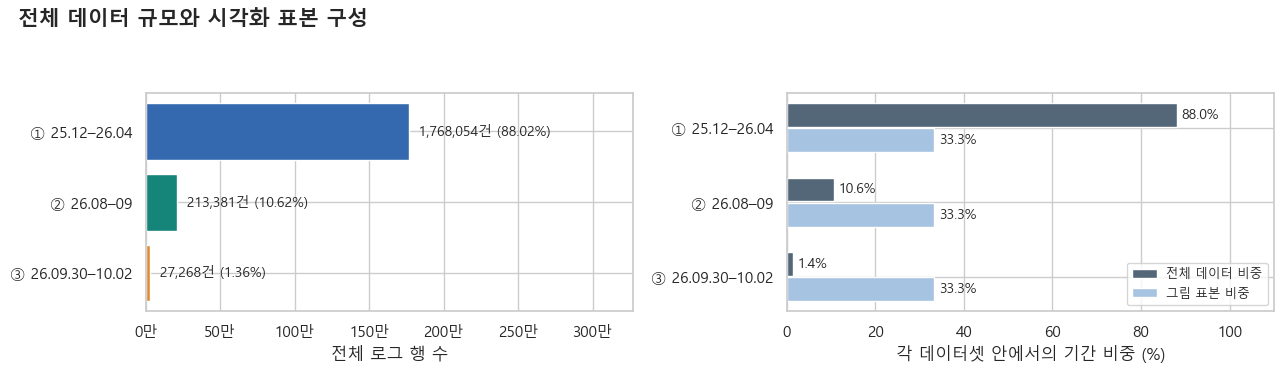

,전체 행 수,그림 표본 행 수,전체 내 비중 (%),표본 내 비중 (%),기간별 추출률 (%)
source_period,,,,,
① 25.12–26.04,1768054,10000,88.020,33.333,0.566
② 26.08–09,213381,10000,10.623,33.333,4.686
③ 26.09.30–10.02,27268,10000,1.357,33.333,36.673


**실제 결과**

- 전체 2,008,703건 중 ① 25.12–26.04가 88.02%입니다. 시각화는 30,000건을 기간별 균형 추출했습니다.

**의미**: 통합 건수 그래프는 가장 큰 기간의 특성을 주로 보여줍니다. 균형 표본은 짧은 기간을 비교하기 위한 것으로 전체 발생 비율을 대표하지 않습니다.

**모델 개발에 반영**: 전체 통계로 발생률을 계산하고, 기간별 표본으로 분포 형태를 비교합니다. 표본 추출률이 큰 최근 기간을 전체 비중으로 오해하지 않습니다.

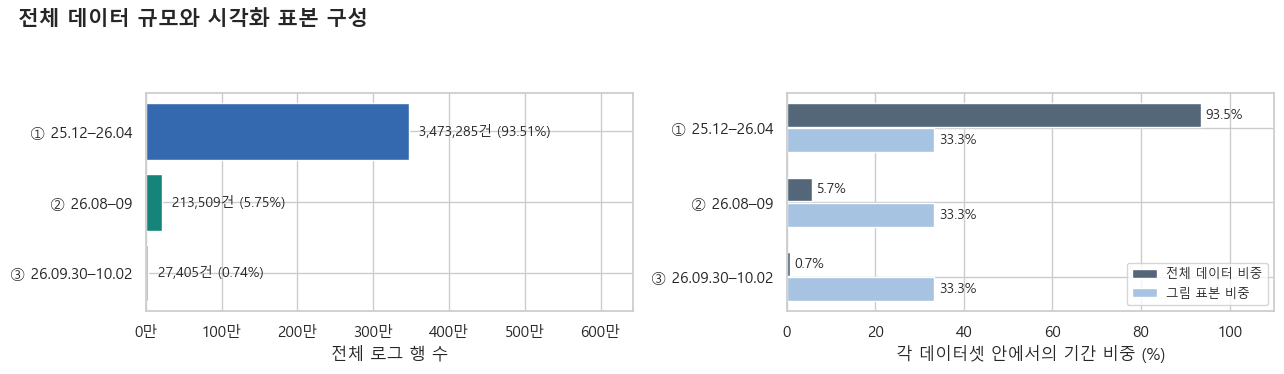

,전체 행 수,그림 표본 행 수,전체 내 비중 (%),표본 내 비중 (%),기간별 추출률 (%)
source_period,,,,,
① 25.12–26.04,3473285,10000,93.514,33.333,0.288
② 26.08–09,213509,10000,5.748,33.333,4.684
③ 26.09.30–10.02,27405,10000,0.738,33.333,36.490


**실제 결과**

- 전체 3,714,199건 중 ① 25.12–26.04가 93.51%입니다. 시각화는 30,000건을 기간별 균형 추출했습니다.

**의미**: 통합 건수 그래프는 가장 큰 기간의 특성을 주로 보여줍니다. 균형 표본은 짧은 기간을 비교하기 위한 것으로 전체 발생 비율을 대표하지 않습니다.

**모델 개발에 반영**: 전체 통계로 발생률을 계산하고, 기간별 표본으로 분포 형태를 비교합니다. 표본 추출률이 큰 최근 기간을 전체 비중으로 오해하지 않습니다.

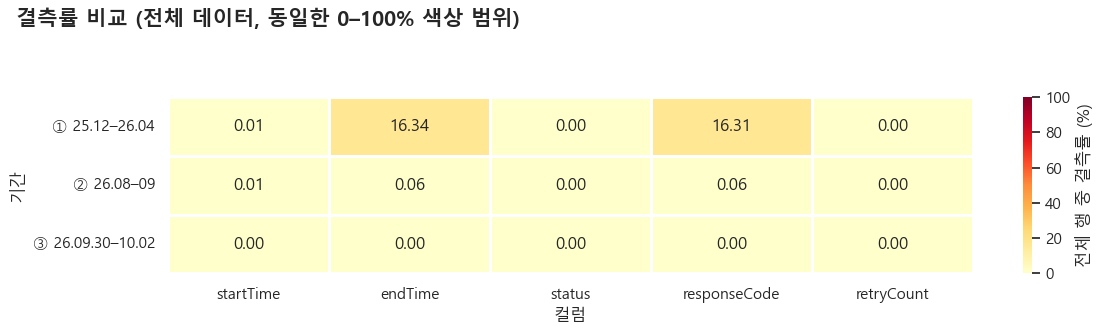

**실제 결과**

- ① 25.12–26.04: 종료시각 결측 567,442건 (16.34%).
- ② 26.08–09: 종료시각 결측 136건 (0.06%).
- ③ 26.09.30–10.02: 종료시각 결측 0건 (0.00%).

**의미**: 종료시각 결측은 처리시간을 계산할 수 없는 로그입니다. 미완료 상태·수집 누락을 구분해야 하며 처리시간 0으로 대치하면 분포가 왜곡됩니다.

**모델 개발에 반영**: 결측 여부 피처를 유지하고, 완료 로그 지연 탐지와 미완료 로그 탐지를 분리합니다. 0.00%는 반올림된 값일 수 있으므로 건수도 확인합니다.

In [5]:
transaction_plot = sample_by_period(transactions, PLOT_SAMPLE, RANDOM_STATE)
process_plot = sample_by_period(processes, PLOT_SAMPLE, RANDOM_STATE)
plot_sampling(transactions, transaction_plot)
plot_sampling(processes, process_plot)
plot_missingness(processes, ["startTime", "endTime", "status", "responseCode", "retryCount"])
del transaction_plot, process_plot


## 2. 결합 키와 1:N 구조 검증

거래 결합 키는 `source_period + transactionId`입니다. 거래 상태가 여러 행이면
큰 `retryCount`, 최신 종료/시작시각 순으로 최종 스냅샷을 선택합니다.
동일 키의 충돌은 감사 표에 남기며, 결측 거래 ID는 결합에서 제외합니다.
프로세스 수는 재시도 포함 실행 행 수와 고유 `processId` 수를 따로 집계합니다.

In [ ]:
JOIN_KEYS = ["source_period", "transactionId"]
tx_state = latest_transaction_state(transactions)
print(f"최종 거래 스냅샷: {len(tx_state):,}건")
print(f"최종 스냅샷 선택/결측 ID로 제외된 거래 행: {len(transactions) - len(tx_state):,}건")
print(f"Process 결측 거래 ID: {processes['transactionId'].isna().sum():,}건")
merged = processes.loc[processes["transactionId"].notna(), JOIN_KEYS + ["processId", "status", "duration_ms", "adapterType"]].merge(
    tx_state[JOIN_KEYS + ["interfaceId", "status", "processCount"]],
    on=JOIN_KEYS, how="left", suffixes=("_process", "_transaction"), indicator=True, validate="many_to_one")
display(pd.crosstab(merged["source_period"], merged["_merge"]))
orphan_processes = merged.loc[merged["_merge"].eq("left_only")]
display(orphan_processes.head(15))
note(f"거래에 연결되지 않은 Process 행 {len(orphan_processes):,}건 / 전체 결합 대상 {len(merged):,}건.",
     "거래 로그 없는 Process는 수집 범위/보존 정책 차이일 수 있습니다. 존재하지 않는 거래에 억지로 결합하면 업무 통계와 모델 입력이 왜곡됩니다.",
     "고아 Process를 별도로 감사하고 같은 기간·거래 키의 연결만 사용합니다.")
del orphan_processes


## 3. 거래 단위 실행 요약과 선언 Process 수 비교

`processCount`와 비교할 값은 고유 프로세스 수입니다. 재시도 포함 실행 행 수와
단순 비교하면 정상 재시도를 불일치로 오인할 수 있습니다.
연결 로그가 없는 거래는 수집 범위 문제일 수 있어 별도로 확인합니다.

In [ ]:
transaction_summary = transaction_process_summary(transactions, processes)
display(transaction_summary.head())
display(transaction_summary.groupby("source_period", observed=True).agg(
    transactions=("transactionId", "size"), no_process=("no_process_logs", "sum"),
    count_comparable=("count_comparable", "sum"), count_mismatches=("count_mismatch_candidate", "sum"),
    total_attempts=("process_attempts", "sum"), total_logical_processes=("distinct_processes", "sum")))
display(transaction_summary.groupby(["source_period", "distinct_processes"], observed=True).size().rename("transactions").head(30))


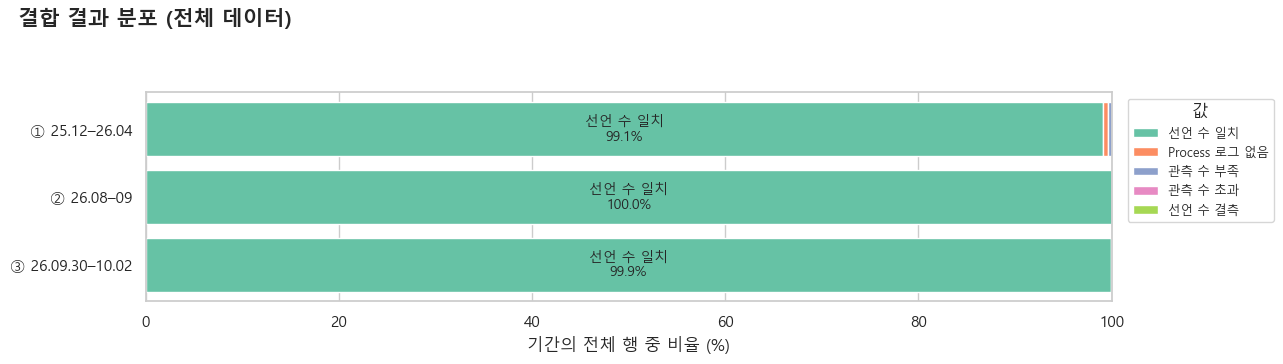

**실제 결과**

- ① 25.12–26.04: 최빈값 선언 수 일치, 1,752,801건 (99.14%).
- ② 26.08–09: 최빈값 선언 수 일치, 213,350건 (99.99%).
- ③ 26.09.30–10.02: 최빈값 선언 수 일치, 27,250건 (99.93%).

**의미**: 기간별 막대의 길이를 100%로 맞췄기 때문에 규모가 아니라 값의 구성 차이를 비교합니다. 처리 건수의 의미·단위는 어댑터마다 다를 수 있습니다.

**모델 개발에 반영**: 연속형 정규분포를 가정하지 않고 범주형/카운트 특성을 반영합니다. 기간·업무 구성이 다른데 공통 IQR을 적용하면 정상 값도 대량 경보가 될 수 있습니다.

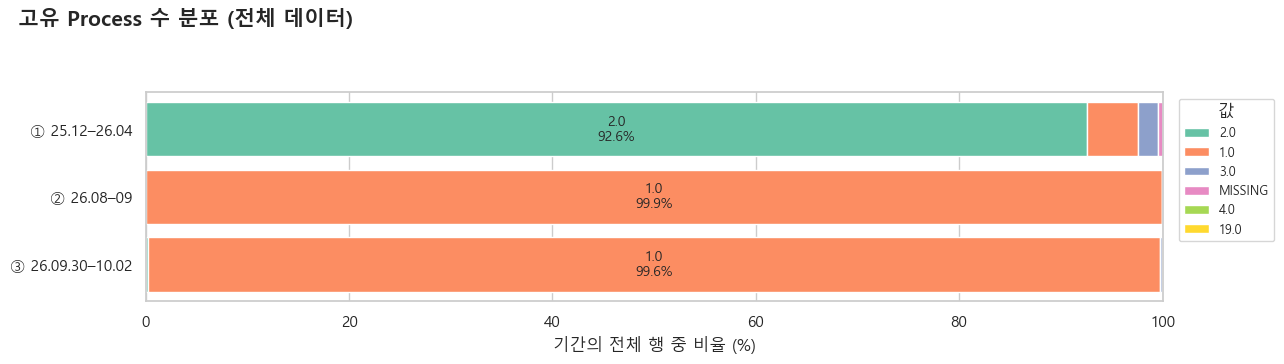

**실제 결과**

- ① 25.12–26.04: 최빈값 2.0, 1,637,311건 (92.61%).
- ② 26.08–09: 최빈값 1.0, 213,260건 (99.94%).
- ③ 26.09.30–10.02: 최빈값 1.0, 27,151건 (99.57%).

**의미**: 기간별 막대의 길이를 100%로 맞췄기 때문에 규모가 아니라 값의 구성 차이를 비교합니다. 처리 건수의 의미·단위는 어댑터마다 다를 수 있습니다.

**모델 개발에 반영**: 연속형 정규분포를 가정하지 않고 범주형/카운트 특성을 반영합니다. 기간·업무 구성이 다른데 공통 IQR을 적용하면 정상 값도 대량 경보가 될 수 있습니다.

**실제 결과**

- Process 로그 없는 거래 8,056건. 선언 수 비교 후보 15,299건(로그 없는 거래와 중복 가능).

**의미**: 결합 결과 막대는 중복 없는 상태 분류입니다. 관측 수가 적으면 로그 누락·업무 정의 차이·실행 미완료를 함께 확인해야 합니다. 재시도 행 수 대신 고유 Process 수를 비교했습니다.

**모델 개발에 반영**: 실행 구조 피처와 결합 누락 여부를 지연 피처와 결합하고, 수집 범위가 다른 로그를 확정 장애로 취급하지 않습니다.

In [8]:
plot_merge_counts(transaction_summary)


## 4. 거래 상태와 최종 프로세스 상태

프로세스별 최신 재시도 스냅샷에서 F가 하나라도 있으면 F, 전부 S면 S,
나머지는 OTHER로 요약합니다. 거래·프로세스 양쪽이 S/F인 경우만 단순 불일치율을
계산합니다. H/Z/P/N 같은 상태의 운영 의미는 이 규칙만으로 확정할 수 없습니다.

process_derived_status,F,NO_PROCESS,OTHER,S
status,,,,
F,132680,5604,299945,22
H,29,0,32,0
P,19,2451,4585,6
S,8,1,1,1563042
Z,0,0,278,0


,comparable,mismatch,mismatch_pct_of_comparable
source_period,,,
25년12월24일-26년4월6일,1455313,26,0.002
26년8월15일-26년9월14일,213230,4,0.002
26년9월30일-26년10월2일,27209,0,0.0


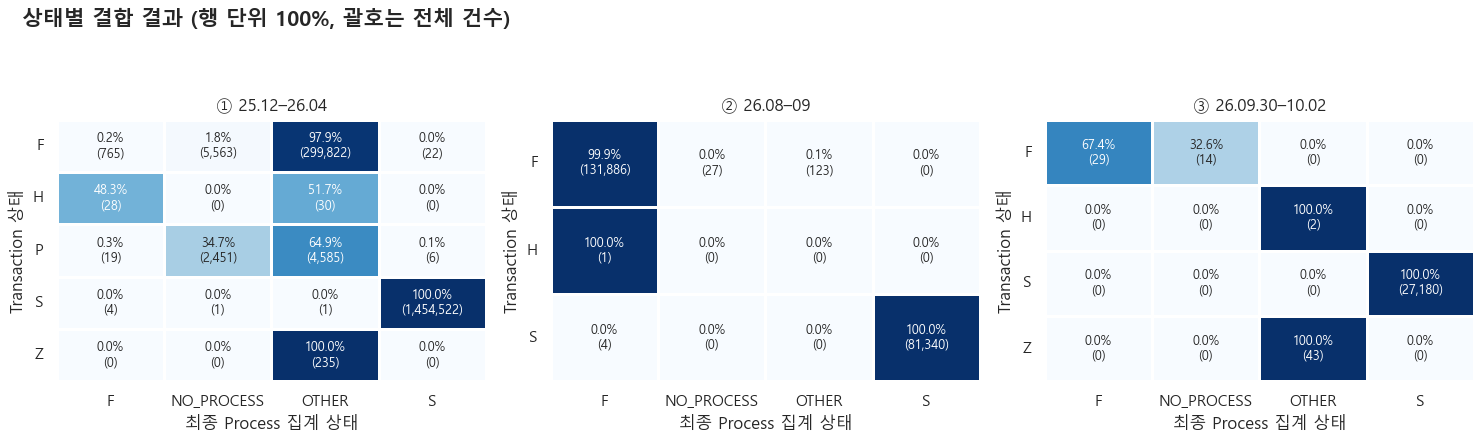

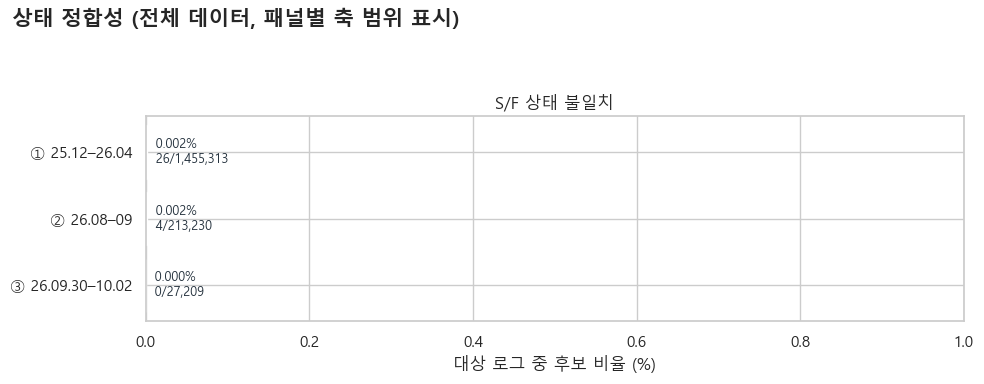

**실제 결과**

- ① 25.12–26.04 / S/F 상태 불일치: 26 / 1,455,313건 (0.002%).
- ② 26.08–09 / S/F 상태 불일치: 4 / 213,230건 (0.002%).
- ③ 26.09.30–10.02 / S/F 상태 불일치: 0 / 27,209건 (0.000%).

**의미**: 분모는 각 규칙의 비교 가능한 로그입니다(별도 조건이 없는 규칙은 기간 전체 행). 서로 다른 규칙의 후보는 중복될 수 있어 합산하면 안 됩니다. 후보 0건과 비교 불가는 다릅니다.

**모델 개발에 반영**: 낮은 비율도 실제 건수로 확인해 검토 대상을 정합니다. 정합성 규칙은 비지도 모델 점수와 별도로 표시하며 확정 장애 라벨로 사용하지 않습니다.

**실제 결과**

- 양쪽이 S/F인 1,695,752건 중 상태 불일치 30건.

**의미**: 거래 상태 한 행을 100%로 정규화해 드문 상태도 읽을 수 있습니다. NO_PROCESS/OTHER는 S/F 불일치 계산에서 제외됩니다. 건수가 적은 상태의 100%는 대표성에 주의해야 합니다.

**모델 개발에 반영**: 부모 거래와 실행 단계의 상태 일관성을 사후 검토 근거로 사용하고, H/Z/P/N의 운영 정의 없이 실패 라벨로 합치지 않습니다.

In [9]:
status_cross = pd.crosstab(text(transaction_summary["status"]), transaction_summary["process_derived_status"])
display(status_cross)
status_quality = transaction_summary.groupby("source_period", observed=True).agg(
    comparable=("status_comparable", "sum"), mismatch=("status_mismatch_candidate", "sum"))
status_quality["mismatch_pct_of_comparable"] = status_quality["mismatch"].div(status_quality["comparable"].replace(0, np.nan)).mul(100)
display(status_quality.round(3))
plot_merge_status(transaction_summary)


## 5. 시간 경계·오버헤드·병목

거래 시작과 첫 Process 시작, 거래 종료와 마지막 Process 종료를 비교합니다.
경계가 같은지를 요구하지 않으며, Process가 거래 범위 밖으로 1ms 이상 벗어나는
경우를 점검 후보로 표시합니다. 병렬 실행이면 Process 시간 합 / 거래 시간은
1을 넘을 수 있으므로 이 값만으로 모순을 판정하지 않습니다.

In [ ]:
PERFORMANCE_COLS = ["duration_ms", "process_span_ms", "process_duration_sum_ms", "bottleneck_duration_ms",
                    "orchestration_overhead_ms", "parallelism_ratio", "start_delta_ms", "end_delta_ms"]
display(numeric_summary(transaction_summary, PERFORMANCE_COLS))
display(transaction_summary.groupby("source_period", observed=True).agg(
    rows=("transactionId", "size"), boundary_candidates=("boundary_candidate", "sum"),
    median_overhead_ms=("orchestration_overhead_ms", "median"), median_parallelism=("parallelism_ratio", "median")))
display(transaction_summary.loc[transaction_summary["boundary_candidate"],
        ["source_period", "transactionId", "start_delta_ms", "end_delta_ms", "duration_ms", "process_span_ms"]].head(20))


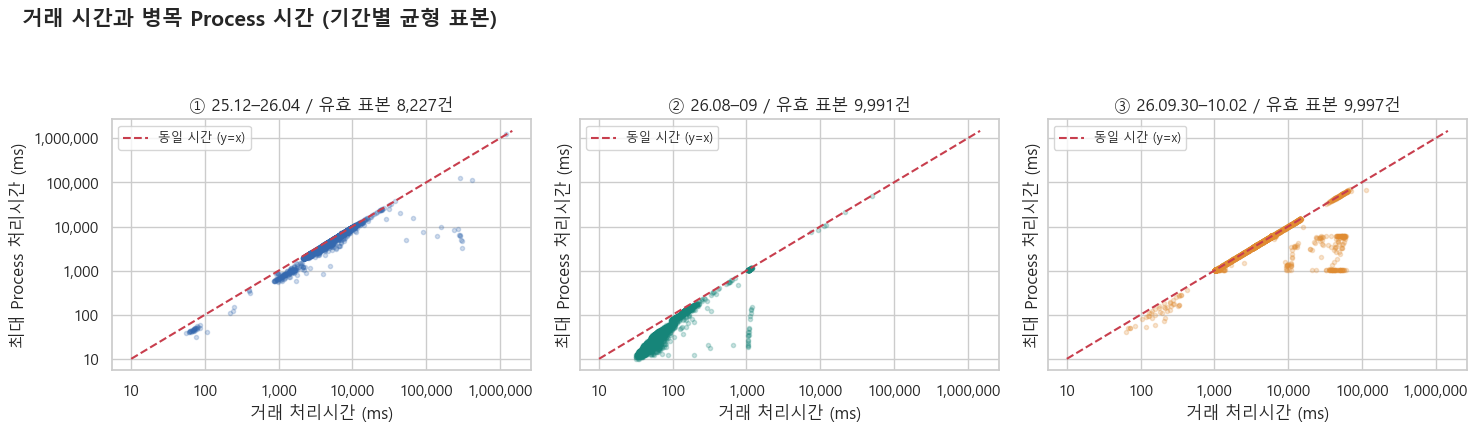

**실제 결과**

- ① 25.12–26.04: 전체 오버헤드 중앙값 30ms, Process 시간 합/거래 시간 중앙값 0.992.
- ② 26.08–09: 전체 오버헤드 중앙값 28ms, Process 시간 합/거래 시간 중앙값 0.529.
- ③ 26.09.30–10.02: 전체 오버헤드 중앙값 12ms, Process 시간 합/거래 시간 중앙값 0.998.

**의미**: y=x 근처는 거래 시간이 가장 긴 Process 시간과 비슷합니다. 아래쪽은 대기·여러 단계 실행·오케스트레이션 시간 등이 포함될 수 있습니다. 두 시계와 로그 범위가 같다는 가정도 확인해야 합니다.

**모델 개발에 반영**: 총 거래 시간 외에 병목 시간·오버헤드·실행 구조를 입력해 어떤 단계가 지연을 만들었는지 설명합니다.

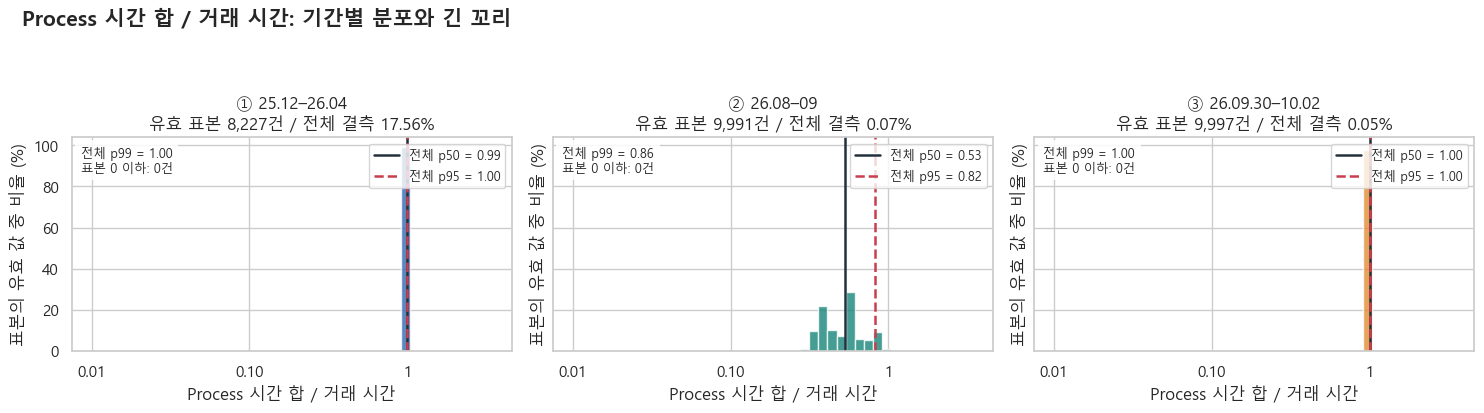

**실제 결과**

- ① 25.12–26.04: 전체 중앙값 0.99, p95 1.00, p99 1.00.
- ② 26.08–09: 전체 중앙값 0.53, p95 0.82, p99 0.86.
- ③ 26.09.30–10.02: 전체 중앙값 1.00, p95 1.00, p99 1.00.

**의미**: 가로축은 로그 간격이지만 눈금은 실제 단위입니다. 히스토그램은 같은 구간·같은 세로축을 사용하는 균형 표본이며 선과 분위수는 전체 데이터입니다. p95보다 큰 값은 전체 유효 값의 최대 약 5%입니다(동률 제외). 표본에 없는 극단값은 히스토그램 범위 밖일 수 있으며 전체 통계 표에서 확인합니다.

**모델 개발에 반영**: 이 값은 시간 합의 비율이며 CPU 병렬도가 아닙니다. 실행 구조와 업무별 정상 범위에 맞춰 모델 피처로 사용하고 1 초과를 단독 이상 규칙으로 쓰지 않습니다.

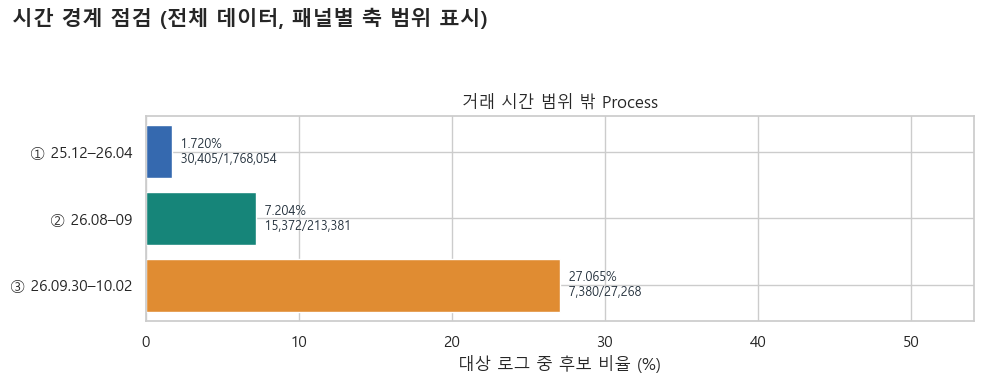

**실제 결과**

- ① 25.12–26.04 / 거래 시간 범위 밖 Process: 30,405 / 1,768,054건 (1.720%).
- ② 26.08–09 / 거래 시간 범위 밖 Process: 15,372 / 213,381건 (7.204%).
- ③ 26.09.30–10.02 / 거래 시간 범위 밖 Process: 7,380 / 27,268건 (27.065%).

**의미**: 분모는 각 규칙의 비교 가능한 로그입니다(별도 조건이 없는 규칙은 기간 전체 행). 서로 다른 규칙의 후보는 중복될 수 있어 합산하면 안 됩니다. 후보 0건과 비교 불가는 다릅니다.

**모델 개발에 반영**: 낮은 비율도 실제 건수로 확인해 검토 대상을 정합니다. 정합성 규칙은 비지도 모델 점수와 별도로 표시하며 확정 장애 라벨로 사용하지 않습니다.

**실제 결과**

- 음수 오버헤드 또는 Process가 거래 범위를 벗어난 후보는 실행 시각/로그 정의를 함께 점검합니다.

**의미**: Process 시간 합/거래 시간은 실제 CPU 병렬도와 같지 않습니다. 1 초과는 병렬 실행으로 설명될 수 있고 시간 경계 후보도 비동기 실행에선 정상일 수 있습니다.

**모델 개발에 반영**: 오버헤드는 부호를 보존한 log1p 피처로 사용하고, 경계 후보는 모델의 정답이 아닌 별도 검토 근거로 유지합니다.

process_rows  median_ms  \
source_period     interfaceId         adapterType                            
25년12월24일-26년4월6일 IF_DB2DB_9xx_DELETE DB.DELETER            144    80230.0   
                  IF_DB2DB_976        DB.WRITER            1582    19466.0   
                  IF_DB2DB_966        DB.WRITER            1669     8804.0   
                  IF_DB2DB_946        DB.WRITER            1578     8255.0   
                  IF_DB2DB_970        DB.WRITER            1496    21660.0   
                  IF_DB2DB_990        DB.WRITER            1868    14675.0   
                  IF_DB2DB_950        DB.WRITER            1709    14390.0   
                  IF_DB2DB_960        DB.WRITER            1018   195157.0   
                  IF_DB2DB_997        DB.WRITER            1488    16493.0   
                  IF_DB2DB_987        DB.WRITER            1698    17017.0   
                  IF_DB2DB_979        DB.WRITER            1904    25435.0   
                  IF_DB2DB_947        DB.WRITER            1361    22372.0   
                  IF_DB2DB_980        DB.WRITER            1965    19004.0   
                  IF_DB2DB_959        DB.WRITER            2112    20913.5   
                  IF_DB2DB_981        DB.WRITER            2215    25348.5   
                  IF_DB2DB_971        DB.WRITER            1503    42589.5   
                  IF_DB2DB_956        DB.WRITER            1874   144145.5   
                  IF_DB2DB_961        DB.WRITER            1687    23294.0   
                  IF_DB2DB_962        DB.WRITER            2497    16845.0   
                  IF_DB2DB_982        DB.WRITER            2330    19599.5   

                                                      p95_ms  
source_period     interfaceId         adapterType             
25년12월24일-26년4월6일 IF_DB2DB_9xx_DELETE DB.DELETER   570741.80  
                  IF_DB2DB_976        DB.WRITER    393243.20  
                  IF_DB2DB_966        DB.WRITER    392532.50  
                  IF_DB2DB_946        DB.WRITER    392420.00  
                  IF_DB2DB_970        DB.WRITER    362698.80  
                  IF_DB2DB_990        DB.WRITER    362124.50  
                  IF_DB2DB_950        DB.WRITER    361553.30  
                  IF_DB2DB_960        DB.WRITER    357328.00  
                  IF_DB2DB_997        DB.WRITER    354138.40  
                  IF_DB2DB_987        DB.WRITER    353086.20  
                  IF_DB2DB_979        DB.WRITER    333542.00  
                  IF_DB2DB_947        DB.WRITER    332949.25  
                  IF_DB2DB_980        DB.WRITER    323226.50  
                  IF_DB2DB_959        DB.WRITER    313563.25  
                  IF_DB2DB_981        DB.WRITER    298954.15  
                  IF_DB2DB_971        DB.WRITER    269022.05  
                  IF_DB2DB_956        DB.WRITER    266413.65  
                  IF_DB2DB_961        DB.WRITER    260361.20  
                  IF_DB2DB_962        DB.WRITER    222861.75  
                  IF_DB2DB_982        DB.WRITER    221695.65

**실제 결과**

- 병목 후보 표는 업무·어댑터별 유효 Process 시간 p95 상위 그룹(실행 30건 이상)입니다.

**의미**: p95가 큰 어댑터는 정상 배치 업무일 수도 있으므로 단독 장애 근거가 아닙니다. 유효 종료시각이 적은 그룹은 지연 분위수 해석에 주의합니다.

**모델 개발에 반영**: 거래의 지연 후보와 해당 실행 단계의 어댑터를 연결해 설명합니다.

In [11]:
summary_plot = sample_by_period(transaction_summary, PLOT_SAMPLE, RANDOM_STATE)
plot_merge_performance(transaction_summary, summary_plot)
bottleneck_profile = merged.groupby(["source_period", "interfaceId", "adapterType"], observed=True).agg(
    process_rows=("processId", "size"), median_ms=("duration_ms", "median"), p95_ms=("duration_ms", lambda s: s.quantile(.95)))
display(bottleneck_profile.loc[bottleneck_profile["process_rows"].ge(30)].sort_values("p95_ms", ascending=False).head(20))
note("병목 후보 표는 업무·어댑터별 유효 Process 시간 p95 상위 그룹(실행 30건 이상)입니다.",
     "p95가 큰 어댑터는 정상 배치 업무일 수도 있으므로 단독 장애 근거가 아닙니다. 유효 종료시각이 적은 그룹은 지연 분위수 해석에 주의합니다.",
     "거래의 지연 후보와 해당 실행 단계의 어댑터를 연결해 설명합니다.")


## 6. 선행 Process와 거래 범위

같은 기간·거래의 선행 로그를 찾고, 재시도가 여러 개면 시간 비교를 유보합니다.
다른 거래에 같은 템플릿이 있다는 사실은 교차 거래 의존성을 뜻하지 않습니다.
스트리밍·병렬 처리의 시간 겹침은 업무별로 해석해야 합니다.

,references,missing,retries_ambiguous,comparable,overlap_candidates,template_only_elsewhere
source_period,,,,,,
25년12월24일-26년4월6일,1713241,5169,0,1450157,104961,5169
26년8월15일-26년9월14일,152,0,0,139,127,0
26년9월30일-26년10월2일,147,0,0,147,147,0


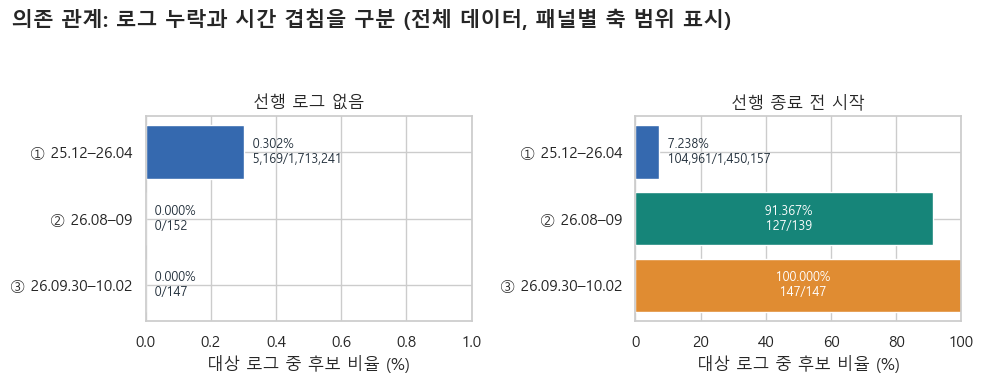

**실제 결과**

- ① 25.12–26.04 / 선행 로그 없음: 5,169 / 1,713,241건 (0.302%).
- ② 26.08–09 / 선행 로그 없음: 0 / 152건 (0.000%).
- ③ 26.09.30–10.02 / 선행 로그 없음: 0 / 147건 (0.000%).
- ① 25.12–26.04 / 선행 종료 전 시작: 104,961 / 1,450,157건 (7.238%).
- ② 26.08–09 / 선행 종료 전 시작: 127 / 139건 (91.367%).
- ③ 26.09.30–10.02 / 선행 종료 전 시작: 147 / 147건 (100.000%).

**의미**: 분모는 각 규칙의 비교 가능한 로그입니다(별도 조건이 없는 규칙은 기간 전체 행). 서로 다른 규칙의 후보는 중복될 수 있어 합산하면 안 됩니다. 후보 0건과 비교 불가는 다릅니다.

**모델 개발에 반영**: 낮은 비율도 실제 건수로 확인해 검토 대상을 정합니다. 정합성 규칙은 비지도 모델 점수와 별도로 표시하며 확정 장애 라벨로 사용하지 않습니다.

**실제 결과**

- 선행 관계 1,713,540건 중 시간 비교 가능 1,450,443건. 선행 로그 없음 5,169건; 시간 겹침 105,235건.

**의미**: 선행 로그 존재와 선행 종료시각 유무는 다른 조건입니다. 시간 겹침은 비동기·스트리밍 실행에서 정상일 수 있으므로 의존 순서 위반으로 단정하지 않습니다.

**모델 개발에 반영**: 선행 로그 누락, 재시도 연결 모호성, 시간 겹침을 별도 피처로 관리하고 업무별 동기/비동기 실행 정의와 비교합니다.

In [12]:
dependency = dependency_features(processes)
display(dependency.groupby(processes["source_period"], observed=True).agg(
    references=("has_predecessor", "sum"), missing=("dependency_missing", "sum"),
    retries_ambiguous=("dependency_retry_ambiguous", "sum"), comparable=("dependency_time_comparable", "sum"),
    overlap_candidates=("dependency_overlap_candidate", "sum"), template_only_elsewhere=("template_only_elsewhere", "sum")))
dependency_tx = dependency.assign(source_period=processes["source_period"], transactionId=processes["transactionId"]).groupby(
    JOIN_KEYS, observed=True)[["dependency_missing", "dependency_overlap_candidate"]].sum()
transaction_summary = transaction_summary.merge(dependency_tx.reset_index(), on=JOIN_KEYS, how="left", validate="one_to_one")
dependency_view = processes[["source_period"]].join(dependency)
plot_dependency(dependency_view)
del dependency_view


## 7. 실행 시퀀스와 드문 업무 흐름

거래 시작 순서 기준 어댑터 시퀀스를 기간별 최대 약 1만 거래에서 확인합니다.
한 거래의 프로세스는 모두 포함하되 재시도는 최신 상태로 정리합니다.
시퀀스 빈도는 표본 기준이며 시작 순서는 의존 관계의 위상 순서와 다를 수 있습니다.
희귀한 정상 업무·신규 업무가 섞일 수 있으므로 빈도만으로 이상을 확정하지 않습니다.

source_period      interfaceId             sequence             
26년9월30일-26년10월2일  IF_TEST_HA_FAILOVER     SERVICE.EXECUTOR         9930
26년8월15일-26년9월14일  IF_CLAUDE_CREATE_001    SERVICE.EXECUTOR         3997
                   IF_REST_ERROR_RESPONSE  SERVICE.EXECUTOR         3831
                   IF_CLAUDE_DELETE_001    SERVICE.EXECUTOR         2161
25년12월24일-26년4월6일  IF_DB2DB_909            DB.READER → DB.WRITER     307
                   IF_DB2DB_903            DB.READER → DB.WRITER     296
                   IF_DB2DB_908            DB.READER → DB.WRITER     291
                   IF_DB2DB_905            DB.READER → DB.WRITER     288
                   IF_DB2DB_915            DB.READER → DB.WRITER     288
                   IF_DB2DB_911            DB.READER → DB.WRITER     283
                   IF_DB2DB_919            DB.READER → DB.WRITER     282
                   IF_DB2DB_904            DB.READER → DB.WRITER     281
                   IF_DB2DB_918            DB.READER → DB.W

,sample_transactions,unique_sequences
source_period,,
25년12월24일-26년4월6일,9951,18
26년8월15일-26년9월14일,9998,6
26년9월30일-26년10월2일,9997,9


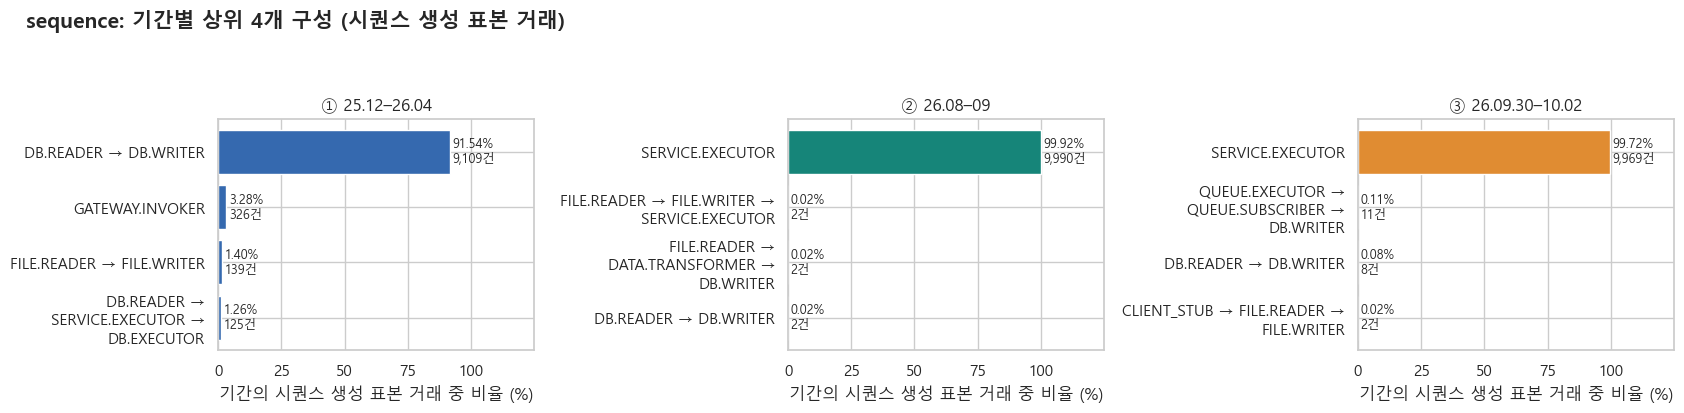

**실제 결과**

- ① 25.12–26.04: 최빈 DB.READER → DB.WRITER가 91.54%, 상위 4개 합계 97.47%.
- ② 26.08–09: 최빈 SERVICE.EXECUTOR가 99.92%, 상위 4개 합계 99.98%.
- ③ 26.09.30–10.02: 최빈 SERVICE.EXECUTOR가 99.72%, 상위 4개 합계 99.93%.

**의미**: 전체 기간을 합산한 순위 대신 각 기간의 상위 범주를 따로 보여줍니다. 업무 구성이나 어댑터 역할이 바뀌면 처리시간과 실패율의 정상 기준도 바뀔 수 있습니다.

**모델 개발에 반영**: 범주별 정상 기준선과 신규 범주 감시를 검토합니다. 상태와 응답코드는 사후 해석용이며 실패 상태 자체를 비지도 모델의 정답으로 사용하지 않습니다.

,추출 거래 수,시퀀스 생성 거래 수,시퀀스 없음
source_period,,,
① 25.12–26.04,10000,9951,49
② 26.08–09,10000,9998,2
③ 26.09.30–10.02,10000,9997,3


**실제 결과**

- 표본 거래 30,000건 중 시퀀스 생성 29,946건. Process 로그 없는 표본은 시퀀스 빈도의 분모에서 제외했습니다.

**의미**: 시퀀스 순위는 전체 거래 통계가 아닌 표본에서 관측한 실행 흐름입니다. 시작 시각 순서와 실제 의존 관계의 순서는 다를 수 있습니다.

**모델 개발에 반영**: 빈도 낮은 시퀀스를 신규 업무/정상 변형/실행 누락으로 나눠 검토하고, 전체 데이터 또는 학습 구간에서 추정한 시퀀스 기준선으로 확장합니다.

In [13]:
sequence_transactions = sample_by_period(tx_state, PLOT_SAMPLE, RANDOM_STATE)[JOIN_KEYS + ["interfaceId"]]
sequence_processes = processes.merge(sequence_transactions, on=JOIN_KEYS, how="inner", validate="many_to_one")
sequence_processes = sequence_processes.sort_values(JOIN_KEYS + ["processId", "retryCount", "endTime"], na_position="first").drop_duplicates(
    JOIN_KEYS + ["processId"], keep="last").sort_values(JOIN_KEYS + ["startTime", "processId"])
sequence_processes["adapter_label"] = text(sequence_processes["adapterType"])
sequences = sequence_processes.groupby(JOIN_KEYS, observed=True).agg(
    interfaceId=("interfaceId", "first"), sequence=("adapter_label", lambda x: " → ".join(x)), steps=("processId", "size"))
sequence_profile = sequences.groupby(["source_period", "interfaceId", "sequence"], observed=True).size().rename("sample_transactions")
display(sequence_profile.sort_values(ascending=False).head(25))
display(sequences.groupby("source_period", observed=True).agg(sample_transactions=("steps", "size"), unique_sequences=("sequence", "nunique")))
plot_sequences(sequences, sequence_transactions)
del sequence_processes


## 8. 거래 단위 시계열과 분포 변화

이하 분석 단위는 원본 프로세스 행이 아니라 최종 거래 스냅샷입니다.
처리시간뿐 아니라 실행 구조와 병렬성·오버헤드 변화도 확인합니다.

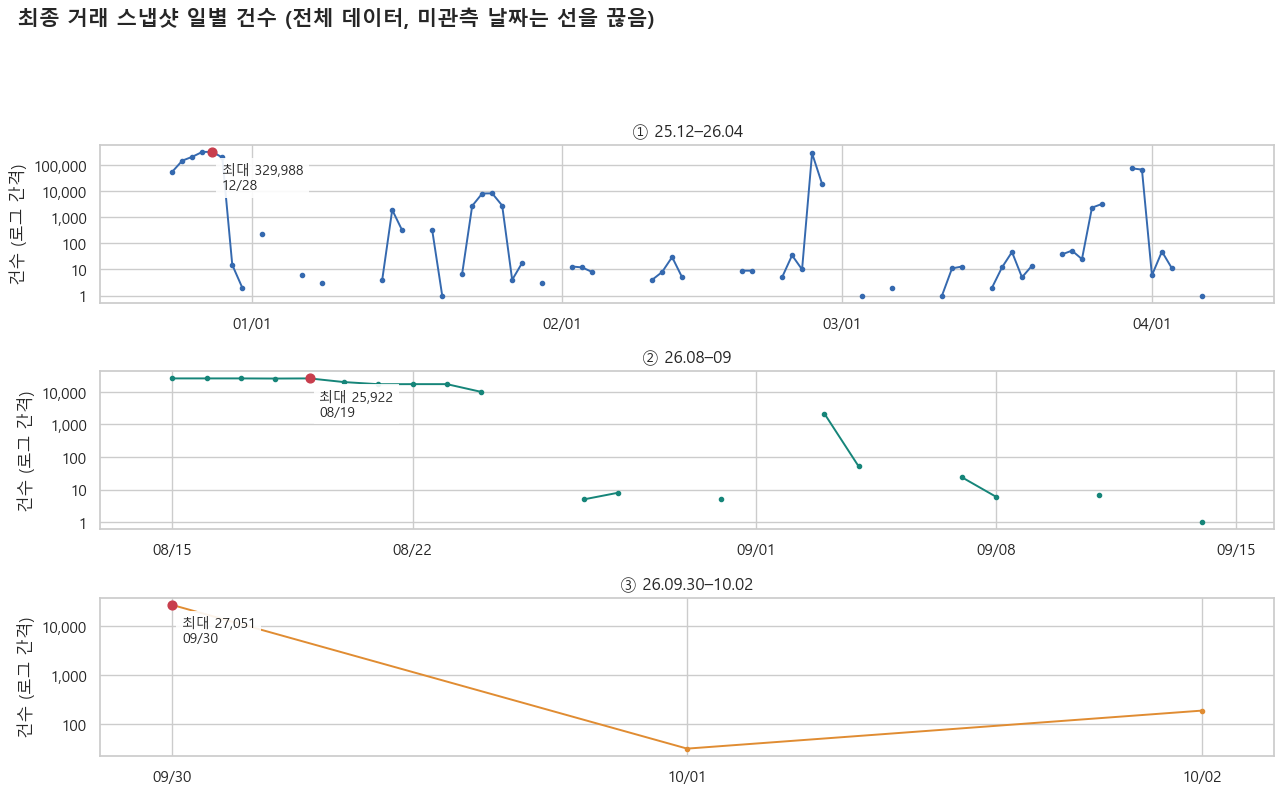

**실제 결과**

- ① 25.12–26.04: 관측 59일, 최대 329,988 (2025-12-28).
- ② 26.08–09: 관측 19일, 최대 25,922 (2026-08-19).
- ③ 26.09.30–10.02: 관측 3일, 최대 27,051 (2026-09-30).

**의미**: 건수·p95는 로그 눈금으로 작은 기간도 읽을 수 있게 했고, 실패율은 동일한 0–100% 범위로 표시했습니다. 수집되지 않은 날짜는 0이 아니라 미관측입니다. 날짜별 p95는 관측 건수가 적으면 불안정합니다.

**모델 개발에 반영**: 시간대·요일·업무량을 조건으로 한 기준선과 지연/실패 동시 변화를 검토합니다. 건수 증가만으로 장애를 판정하지 않습니다.

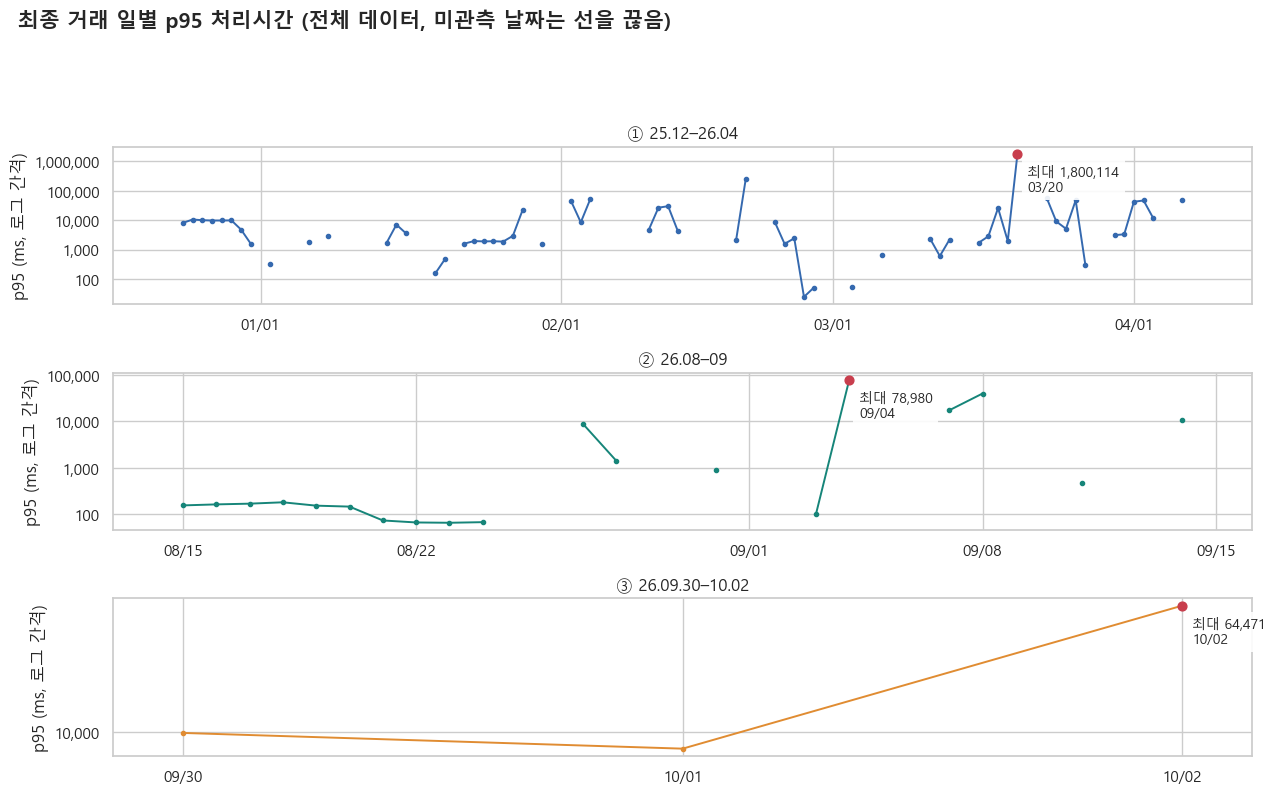

**실제 결과**

- ① 25.12–26.04: 관측 59일, 최대 1,800,114 (2026-03-20).
- ② 26.08–09: 관측 19일, 최대 78,980 (2026-09-04).
- ③ 26.09.30–10.02: 관측 3일, 최대 64,471 (2026-10-02).

**의미**: 건수·p95는 로그 눈금으로 작은 기간도 읽을 수 있게 했고, 실패율은 동일한 0–100% 범위로 표시했습니다. 수집되지 않은 날짜는 0이 아니라 미관측입니다. 날짜별 p95는 관측 건수가 적으면 불안정합니다.

**모델 개발에 반영**: 시간대·요일·업무량을 조건으로 한 기준선과 지연/실패 동시 변화를 검토합니다. 건수 증가만으로 장애를 판정하지 않습니다.

In [14]:
df = transaction_summary
daily = time_summary(df, "D")
plot_period_timeseries(daily, "rows", "최종 거래 스냅샷 일별 건수")
plot_period_timeseries(daily, "p95_ms", "최종 거래 일별 p95 처리시간")
df["integrity_candidate"] = df[["count_mismatch_candidate", "status_mismatch_candidate", "boundary_candidate"]].any(axis=1)


## 9. 기간별 분포 변화와 새로운 범주

첫 기간을 기준으로 수치형 PSI와 새로운 업무·경로 비율을 비교합니다.
PSI는 기준 기간의 고정 분위수 구간을 사용하며 0에 가까울수록 분포가 유사합니다.
기준 기간의 범위를 벗어난 값과 상수였던 변수의 새 값도 별도 구간에 집계합니다.
구간 수와 관측 행 수도 함께 확인하며 분위수와 결측률을 같이 비교합니다.
기간 차이는 운영 환경·업무·수집 범위 변화일 수 있어 이상으로 바로 확정하지 않습니다.

,feature,source_period,reference_rows,current_nonmissing,bins,PSI,median,p99,missing_pct
0,duration_ms,25년12월24일-26년4월6일,1760994,1760994,12,0.0000,5458.0000,10952.0000,0.3993
1,duration_ms,26년8월15일-26년9월14일,1760994,213381,12,10.0313,58.0000,398.2000,0.0000
2,duration_ms,26년9월30일-26년10월2일,1760994,27268,12,2.8529,5984.0000,52072.9700,0.0000
3,process_attempts,25년12월24일-26년4월6일,1760039,1760039,4,0.0000,2.0000,3.0000,0.4533
4,process_attempts,26년8월15일-26년9월14일,1760039,213354,4,10.1310,1.0000,1.0000,0.0127
5,process_attempts,26년9월30일-26년10월2일,1760039,27254,4,8.0588,1.0000,1.0000,0.0513
6,distinct_processes,25년12월24일-26년4월6일,1760039,1760039,4,0.0000,2.0000,3.0000,0.4533
7,distinct_processes,26년8월15일-26년9월14일,1760039,213354,4,10.1310,1.0000,1.0000,0.0127
8,distinct_processes,26년9월30일-26년10월2일,1760039,27254,4,8.0588,1.0000,1.0000,0.0513
9,bottleneck_duration_ms,25년12월24일-26년4월6일,1457669,1457669,12,0.0000,5805.0000,10357.0000,17.5552


,feature,source_period,unique_values,new_values,new_value_row_pct
0,interfaceId,25년12월24일-26년4월6일,365,0,0.000
1,interfaceId,26년8월15일-26년9월14일,47,31,99.974
2,interfaceId,26년9월30일-26년10월2일,12,10,99.879
3,startChannelId,25년12월24일-26년4월6일,9,0,0.000
4,startChannelId,26년8월15일-26년9월14일,5,1,0.002
5,startChannelId,26년9월30일-26년10월2일,2,0,0.000
6,endChannelId,25년12월24일-26년4월6일,10,0,0.000
7,endChannelId,26년8월15일-26년9월14일,4,1,0.002
8,endChannelId,26년9월30일-26년10월2일,2,0,0.000


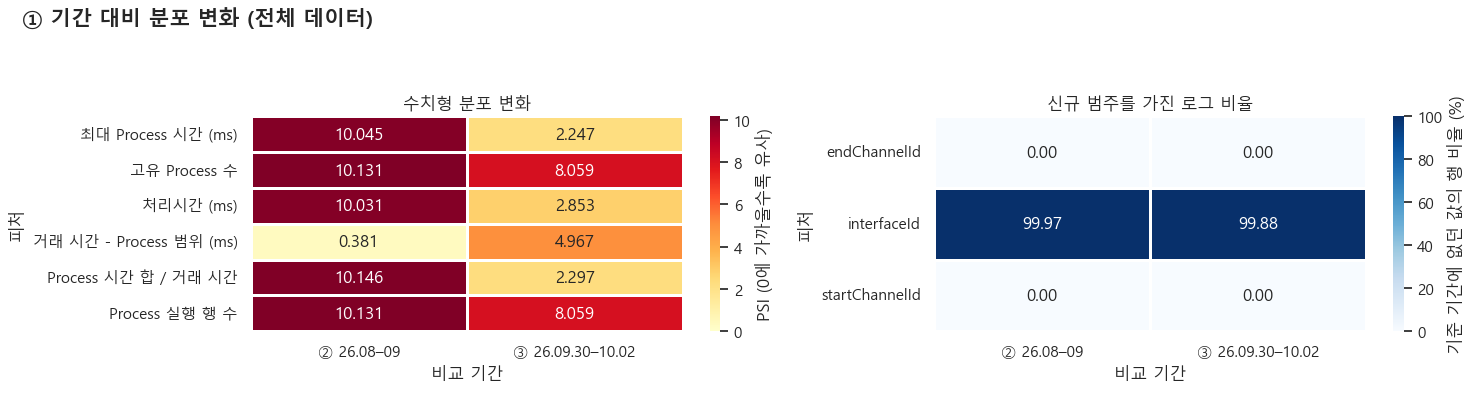

**실제 결과**

- ② 26.08–09 / Process 시간 합 / 거래 시간: PSI 10.146.
- ② 26.08–09 / Process 실행 행 수: PSI 10.131.
- ② 26.08–09 / 고유 Process 수: PSI 10.131.
- ② 26.08–09 / interfaceId: 기준 기간에 없던 값을 가진 로그 99.97%.

**의미**: 여러 피처와 업무 ID가 함께 바뀌면 처리 방식·업무 구성·수집 범위 변화(도메인 변화)를 우선 의심합니다. PSI는 분포 차이 지표이며 실제 이상 비율이 아닙니다. 상수 피처의 극소 PSI는 표본 크기와 평활화 때문일 수 있습니다.

**모델 개발에 반영**: 전체 기간 공통 모델과 업무/운영 환경별 기준 모델을 비교합니다. 새 범주 로그는 지연·정합성 증거를 함께 검토하며 신규 업무라는 이유만으로 장애로 확정하지 않습니다.

In [15]:
drift_numeric = numeric_drift(df, ['duration_ms', 'process_attempts', 'distinct_processes', 'bottleneck_duration_ms', 'orchestration_overhead_ms', 'parallelism_ratio'])
drift_categories = categorical_drift(df, ['interfaceId', 'startChannelId', 'endChannelId'])
display(drift_numeric.round(4))
display(drift_categories.round(3))
plot_drift(drift_numeric, drift_categories)


### 9.1 수치 피처 간 중복 정보

긴 꼬리에 강한 Spearman 상관계수를 기간별 균형 표본에서 확인합니다.
강한 상관관계나 전부 결측·상수인 피처는 모델 입력을 검토할 때 참고합니다.

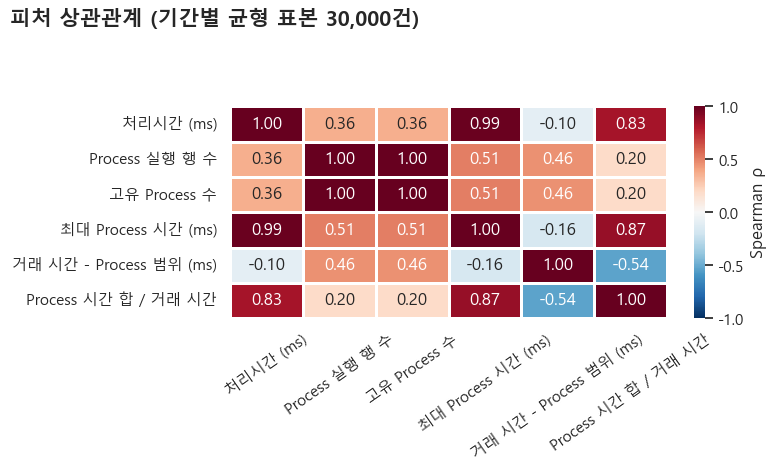

**실제 결과**

- 가장 강한 관계: process_attempts–distinct_processes, ρ=1.000.
- 가장 강한 관계: duration_ms–bottleneck_duration_ms, ρ=0.986.
- 상수/유효값 부족으로 상관 계산 불가: 없음.

**의미**: 회색/빈 칸은 상관 0이 아니라 계산 불가입니다. 통합 표본의 상관은 기간 간 차이 때문에 커질 수도 있어 인과관계나 그룹 내부 관계로 바로 해석하지 않습니다.

**모델 개발에 반영**: 중복 피처를 줄이고 기간/업무별 상관도 대조합니다. 상수 피처 제거와 데이터 단위 확인 후 모델 입력을 결정합니다.

In [16]:
corr_sample = sample_by_period(df, PLOT_SAMPLE, RANDOM_STATE)
plot_correlation(corr_sample, ['duration_ms', 'process_attempts', 'distinct_processes', 'bottleneck_duration_ms', 'orchestration_overhead_ms', 'parallelism_ratio'])


## 10. 시간 순서 검증을 갖춘 비지도 기준 모델

Isolation Forest에 처리시간·로그 건수·재시도·순환 시간 피처·업무 범주 빈도를
입력합니다. 거래 ID와 데이터 기간은 입력에서 제외하고, `status`, `responseCode`,
성공/오류 건수와 정합성 후보는 사후 해석에만 사용합니다.

관측 날짜 순서로 약 60%/20%/20%를 학습/검증/시험으로 나눕니다.
같은 거래의 로그는 같은 분할에 두고, 분할 경계를 넘는 거래는 평가에서 제외합니다.
결측 대치·스케일링·범주 빈도는 학습 구간에서만 정합니다.
전체 학습 구간의 범주 빈도를 사용하되 모델 학습은 최대 10만 행,
점수 산출은 10만 행씩 처리해 메모리를 제한합니다.

임계값은 검증 점수의 99% 분위수입니다. 이는 검토량을 정하는 운영 설정이며
실제 이상 비율 추정치가 아닙니다. 시험 데이터에는 고정한 임계값을 적용합니다.
정답 라벨이 없으므로 accuracy/F1/precision으로 성능을 주장하지 않습니다.

In [17]:
MODEL_NUMERIC = ['duration_ms', 'processCount', 'retryCount', 'process_attempts', 'distinct_processes', 'bottleneck_duration_ms', 'orchestration_overhead_ms', 'parallelism_ratio']
MODEL_CATEGORICAL = ['interfaceId', 'startChannelId', 'endChannelId', 'interfaceType']
model_result, model_profile, fitted = fit_anomaly_baseline(
    df, MODEL_NUMERIC, MODEL_CATEGORICAL, max_train=MAX_TRAIN_ROWS,
    batch_size=SCORE_BATCH_ROWS, alert_quantile=ALERT_QUANTILE, random_state=RANDOM_STATE)
display(pd.DataFrame([{k: v for k, v in model_profile.items() if k != "features"}]).T.rename(columns={0: "값"}))
display(baseline_report(df, model_result))
split_times = df[["source_period", "startTime"]].assign(split=model_result["split"]).groupby(
    ["source_period", "split"], observed=True).agg(rows=("startTime", "size"), first=("startTime", "min"), last=("startTime", "max"))
display(split_times)
note(f"학습 전체 {model_profile['training_rows']:,}건, 실제 모델 학습 표본 {model_profile['training_sample_rows']:,}건; "
     f"검증 {model_profile['validation_rows']:,}건, 시험 {model_profile['test_rows']:,}건.",
     "날짜 단위 약 60/20/20 분할이므로 행 수의 비율이 60/20/20일 필요는 없습니다. 학습 기간에 없던 업무 구성은 시험 시 분포 변화로 나타날 수 있습니다.",
     "시간 분리와 거래 단위 그룹을 유지하고, 기준 모델의 경보량을 업무별 모델과 비교합니다.")


,값
training_rows,1.616874e+06
training_sample_rows,1.000000e+05
validation_rows,2.805260e+05
test_rows,1.113030e+05
feature_count,2.700000e+01
validation_quantile,9.900000e-01
threshold,7.471764e-01


rows  scored_rows  mean_score  candidates  \
source_period     split                                                      
25년12월24일-26년4월6일 train       1616874      1616874      0.4404        1998   
                  validation   151180       151180      0.4981         255   
26년8월15일-26년9월14일 test          84035        84035      0.7319        8324   
                  validation   129346       129346      0.7271        2594   
26년9월30일-26년10월2일 test          27268        27268      0.6821          54   

                              candidate_pct  
source_period     split                      
25년12월24일-26년4월6일 train              0.1236  
                  validation         0.1687  
26년8월15일-26년9월14일 test               9.9054  
                  validation         2.0055  
26년9월30일-26년10월2일 test               0.1980

rows                   first  \
source_period     split                                         
25년12월24일-26년4월6일 train       1616874 2025-12-24 10:25:31.632   
                  validation   151180 2026-03-23 08:12:59.258   
26년8월15일-26년9월14일 test          84035 2026-08-20 00:00:00.284   
                  validation   129346 2026-08-15 00:00:00.257   
26년9월30일-26년10월2일 test          27268 2026-09-30 09:49:26.483   

                                                last  
source_period     split                               
25년12월24일-26년4월6일 train      2026-03-20 17:04:21.488  
                  validation 2026-04-06 08:51:33.002  
26년8월15일-26년9월14일 test       2026-09-14 14:19:58.603  
                  validation 2026-08-19 23:59:55.035  
26년9월30일-26년10월2일 test       2026-10-02 15:36:59.444

**실제 결과**

- 학습 전체 1,616,874건, 실제 모델 학습 표본 100,000건; 검증 280,526건, 시험 111,303건.

**의미**: 날짜 단위 약 60/20/20 분할이므로 행 수의 비율이 60/20/20일 필요는 없습니다. 학습 기간에 없던 업무 구성은 시험 시 분포 변화로 나타날 수 있습니다.

**모델 개발에 반영**: 시간 분리와 거래 단위 그룹을 유지하고, 기준 모델의 경보량을 업무별 모델과 비교합니다.

### 10.1 시험 구간의 점수와 검토 후보

후보 비율과 상위 점수를 기간별로 확인합니다. 새로운 기간의 대량 경보는
실제 장애뿐 아니라 분포 변화나 로그 수집 차이 때문일 수 있습니다.
상태·정합성 규칙과의 교차표는 해석을 돕는 참고값으로만 봅니다.

In [ ]:
top_index = model_result.loc[model_result["split"].eq("test") & model_result["anomaly_candidate"]].nlargest(20, "anomaly_score").index
display(df.loc[top_index, ['source_period', 'transactionId', 'startTime', 'interfaceId', 'status', 'duration_ms', 'process_attempts', 'distinct_processes', 'bottleneck_duration_ms', 'count_mismatch_candidate', 'status_mismatch_candidate', 'boundary_candidate']].join(model_result[["anomaly_score"]]))


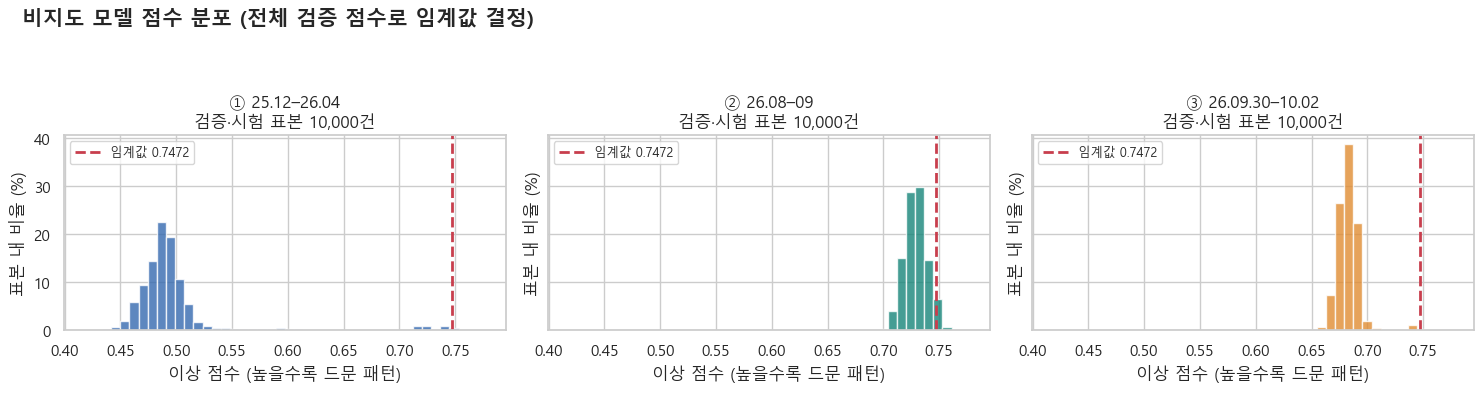

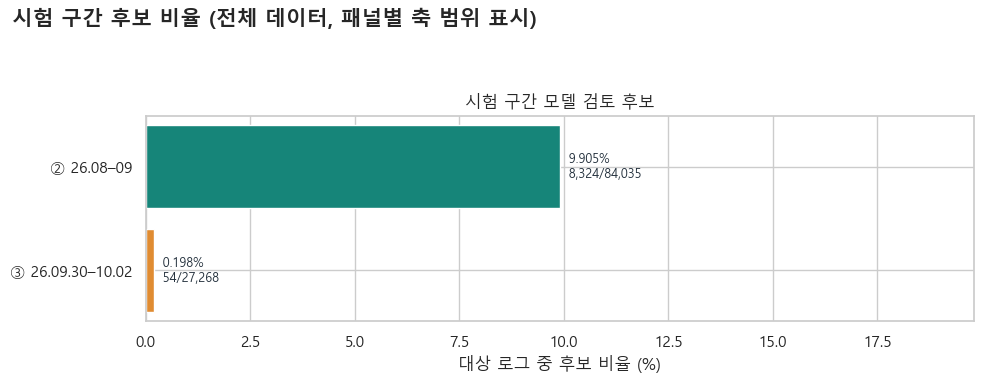

**실제 결과**

- ② 26.08–09 / 시험 구간 모델 검토 후보: 8,324 / 84,035건 (9.905%).
- ③ 26.09.30–10.02 / 시험 구간 모델 검토 후보: 54 / 27,268건 (0.198%).

**의미**: 분모는 각 규칙의 비교 가능한 로그입니다(별도 조건이 없는 규칙은 기간 전체 행). 서로 다른 규칙의 후보는 중복될 수 있어 합산하면 안 됩니다. 후보 0건과 비교 불가는 다릅니다.

**모델 개발에 반영**: 낮은 비율도 실제 건수로 확인해 검토 대상을 정합니다. 정합성 규칙은 비지도 모델 점수와 별도로 표시하며 확정 장애 라벨로 사용하지 않습니다.

**실제 결과**

- 시험 전체 111,303건 중 후보 8,378건 (7.53%). 임계값 0.7472; 검증 점수의 99% 분위수입니다.

**의미**: 히스토그램은 표본이지만 시험 후보율은 전체 시험 로그로 계산했습니다. 99% 검증 분위수를 적용해도 기간 변화와 점수 동률 때문에 시험 후보율이 1%일 필요는 없습니다.

**모델 개발에 반영**: 이 비율은 정확도가 아니라 사람이 검토할 양입니다. 상태·업무·수집 변화와 후보를 교차 검토하고 실제 장애 확인 표본으로 precision/recall을 평가합니다.

In [19]:
plot_model_scores(df, model_result, model_profile)


### 10.2 후보의 상태·정합성은 사후 해석입니다

후보/비후보 각각을 100%로 맞춘 교차표입니다. `status=F`를 정답으로 둔
학습·평가가 아니므로 실패 상태가 많은 것을 precision으로 해석하지 않습니다.

In [20]:
test_view = df.loc[model_result["split"].eq("test"), ["status", 'integrity_candidate']].join(model_result[["anomaly_candidate"]])
display(pd.crosstab(test_view["anomaly_candidate"], text(test_view["status"]), normalize="index").mul(100).round(2))
display(pd.crosstab(test_view["anomaly_candidate"], test_view['integrity_candidate'], normalize="index").mul(100).round(2))
note("위 표의 각 행은 후보 또는 비후보 집단 내부의 상태/정합성 비율입니다. 두 집단의 건수는 서로 다릅니다.",
     "후보는 희귀한 행동 패턴입니다. 실패 상태·정합성 후보와 겹칠 수 있지만 같지 않으며, 성공 상태의 후보도 검토 대상입니다.",
     "상위 점수와 상태·업무·지연 근거를 함께 검토해 실제 이상 라벨을 확보합니다.")
del test_view


status,F,H,S,Z
anomaly_candidate,,,,
False,64.54,0.0,35.42,0.04
True,96.24,0.0,3.76,0.00


integrity_candidate,False,True
anomaly_candidate,,
False,82.09,17.91
True,84.38,15.62


**실제 결과**

- 위 표의 각 행은 후보 또는 비후보 집단 내부의 상태/정합성 비율입니다. 두 집단의 건수는 서로 다릅니다.

**의미**: 후보는 희귀한 행동 패턴입니다. 실패 상태·정합성 후보와 겹칠 수 있지만 같지 않으며, 성공 상태의 후보도 검토 대상입니다.

**모델 개발에 반영**: 상위 점수와 상태·업무·지연 근거를 함께 검토해 실제 이상 라벨을 확보합니다.

### 10.3 PCA로 보는 피처 공간

PCA는 학습 데이터에만 맞추고 기간별 균형 표본을 투영합니다.
그림은 구조를 살펴보는 2차원 요약이며 분리되어 보인다는 사실만으로 이상을 확정하지 않습니다.

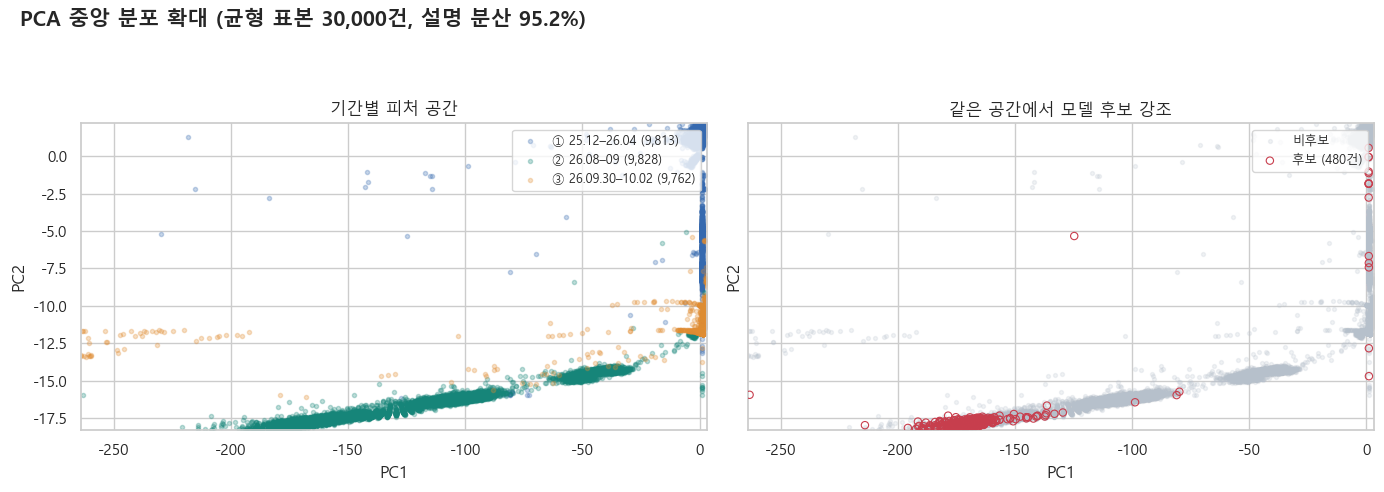

**실제 결과**

- 각 축의 표본 0.5–99.5% 범위를 확대했습니다. 화면 밖 597건 중 후보 77건은 모델 계산에서 제외하지 않았습니다. 전체 투영 표본 후보 557건.

**의미**: 왼쪽은 기간 차이, 오른쪽은 후보의 위치를 보여줍니다. PCA 2축은 전체 피처 정보의 일부만 보존하므로 떨어진 군집이나 점 하나를 실제 이상으로 확정할 수 없습니다.

**모델 개발에 반영**: 분리된 기간은 도메인 변화의 단서로 보고 원래 피처와 업무 종류를 확인합니다. 화면 밖 후보도 상위 점수 표로 함께 검토합니다.

0                       log_duration_ms
1                   missing_duration_ms
2                      log_processCount
3                  missing_processCount
4                    missing_retryCount
5                  log_process_attempts
6              missing_process_attempts
7                log_distinct_processes
8            missing_distinct_processes
9            log_bottleneck_duration_ms
10       missing_bottleneck_duration_ms
11        log_orchestration_overhead_ms
12    missing_orchestration_overhead_ms
13                log_parallelism_ratio
14            missing_parallelism_ratio
15                             hour_sin
16                             hour_cos
17                          weekday_sin
18                          weekday_cos
19                   rarity_interfaceId
20                   unseen_interfaceId
21                rarity_startChannelId
22                unseen_startChannelId
23                  rarity_endChannelId
24                  unseen_endChannelId


In [21]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(fitted["X_train"])
pca_sample = sample_by_period(df.loc[model_result["anomaly_score"].notna()], PLOT_SAMPLE, RANDOM_STATE)
coords = pca.transform(fitted["transform"](pca_sample))
projection = pd.DataFrame(coords, columns=["PC1", "PC2"], index=pca_sample.index)
projection["source_period"] = pca_sample["source_period"]
projection["candidate"] = model_result.loc[pca_sample.index, "anomaly_candidate"]
plot_projection(projection, pca.explained_variance_ratio_.sum())
display(pd.Series(model_profile["features"], name="model_input_feature"))


## 11. 모델 개발로 이어지는 해석

- 통합 분포와 기간별 변화가 크면 업무 그룹 기준선과 운영 환경별 모델을 비교합니다.
- 처리시간의 긴 꼬리에는 로그 변환을, 시간 주기에는 sin/cos 표현을 사용합니다.
- 거래 ID는 결합 키이며 모델 입력에서 제외합니다. 업무 ID는 범주 빈도나 별도 표현을 검토합니다.
- 결측·재시도·수집 범위가 만든 후보와 실제 실행 이상 후보를 사람 검토로 구분합니다.
- 실제 성능 평가는 검토로 확정된 표본이나 통제된 장애 주입 데이터가 필요합니다.
- 이후 비교 모델은 LOF/강건 공분산/Autoencoder 및 시계열 예측 잔차 모델로 확장할 수 있습니다.
  모든 대치·변환·기준선·임계값은 학습/검증 단계에서만 결정합니다.